 **Celem niniejszego pliku** jest analiza zbioru danych i jego wstepne przygotowanie pod dalsze zadania realizowane w ramach projektu.

W ramach przygotowania danych wykorzystujemy zbiór RAISE, zawierający zdjęcia w formacie RAW. Na podstawie oryginalnych zdjęć generujemy dwie wersje obrazów:

- **Ground Truth** – prawidłowo naświetlony obraz referencyjny.

- **Low Light Input** – obraz z obniżoną ekspozycją o 3 EV oraz zasymulowanym szumem matrycy aparatu.

Tak przygotowane pary obrazów będą wykorzystywane w dalszym etapie projektu do trenowania i testowania sieci neuronowej, której zadaniem będzie odtworzenie poprawnie naświetlonego obrazu.

## 1. Analiza pliku **CSV**

W tej sekcji wczytujemy plik metadanych `RAISE_258.csv`, aby zweryfikować strukturę zbioru danych.

Wykorzystujemy bibliotekę Pandas, która umożliwia odczytanie danych oraz analizę struktury tabeli.

Sprawdzamy:

- liczbę rekordów w zbiorze,

- liczbę i nazwy kolumn,

- identyfikatory zdjęć,

- adresy URL prowadzące do plików RAW w formacie NEF.

Szczególnie istotne są kolumny File oraz NEF. Pierwsza zawiera nazwy plików, natomiast druga umożliwia pobranie odpowiadających im zdjęć.

Dane z CSV stanowią podstawę do automatyzacji dalszego procesu przygotowania zbioru obrazów.

In [5]:
import pandas as pd

df = pd.read_csv("/content/RAISE_258.csv")

print("Name of col:", df.columns.tolist(),"\n")
print("Numbers of col:", len(df.columns))
print("Numbers of rows:", len(df), "\n")

df[["File", "NEF"]].head(3)

Name of col: ['File', 'NEF', 'TIFF', 'Date Created', 'Date Modified', 'File Size', 'Image Size', 'Date Shot', 'Time Zone and Date', 'Image Quality', 'Artist', 'Copyright', 'Image Comment', 'Device', 'Lens', 'Focal Length', 'Focus Mode', 'AF-Area Mode', 'VR', 'AF Fine Tune', 'Aperture', 'Shutter Speed', 'Exposure Mode', 'Exposure Comp.', 'Exposure Tuning', 'Metering', 'ISO Sensitivity', 'Flash Device', 'Flash Sync Mode', 'Flash Mode', 'White Balance', 'Color Space', 'High ISO NR', 'Long Exposure NR', 'Active D-Lighting', 'Image Authentication', 'Vignette Control', 'Auto Distortion Control', 'Picture Control', 'Base', 'Quick Adjust', 'Sharpening', 'Contrast', 'Brightness', 'Saturation', 'Hue', 'Filter Effects', 'Toning', 'Optimize Image', 'Color Mode', 'Tone Comp.', 'Hue Adjustment', 'Saturation.1', 'Sharpening.1', 'Latitude', 'Longitude', 'Altitude', 'Altitude Reference', 'Heading', 'UTC', 'Map Datum', 'Scene Mode', 'Keywords'] 

Numbers of col: 63
Numbers of rows: 633 



,File,NEF
0,rfcf40796t,http://193.205.194.113/RAISE/NEF/rfcf40796t.NEF
1,ra5689909t,http://193.205.194.113/RAISE/NEF/ra5689909t.NEF
2,r5714d7e2t,http://193.205.194.113/RAISE/NEF/r5714d7e2t.NEF


### Wnioski z wstępnej inspekcji:
* **Liczba rekordów:** W analizowanym podzbiorze znajduje się **633** unikalne rekordy (zdjęcia).
* **Struktura:** Tabela posiada **63 kolumny** zawierające m.in. unikalne identyfikatory (`File`), bezpośrednie linki do surowych plików graficznych RAW w formacie `.NEF` oraz parametry ekspozycji i sprzętu fotograficznego.
* **Cel:** Kolumna `NEF` posłuży do zautomatyzowanego pobierania plików źródłowych bezpośrednio z serwera bazy danych w kolejnych etapach przygotowania zbioru treningowego i testowego.

### 2. Pobieranie i zapisywanie surowych plików NEF


W tej części przygotowujemy funkcję download_raise_nef(), której zadaniem jest automatyczne pobieranie zdjęć ze zbioru RAISE.

Funkcja odczytuje kolejne rekordy z pliku CSV, pobiera adres URL zdjęcia oraz jego nazwę, a następnie zapisuje plik RAW w wybranym katalogu.

Zastosowano również kilka usprawnień:

- możliwość ograniczenia liczby pobieranych zdjęć za pomocą parametru limit,

- automatyczne tworzenie katalogu docelowego,

- pomijanie plików, które zostały już wcześniej pobrane,

- pobieranie danych w mniejszych fragmentach.

Dzięki temu proces pobierania jest łatwiejszy do kontrolowania i można go bezpiecznie ponawiać.

In [6]:
import os
import csv
import requests


def download_raise_nef(csv_path, output_dir, limit=None):
    os.makedirs(output_dir, exist_ok=True)
    with open(csv_path, mode='r', encoding='utf-8') as file:
        csv_reader = csv.DictReader(file)
        for i, row in enumerate(csv_reader):
            if limit is not None and i >= limit:
                break
            nef_url = row['NEF']
            filename = row['File']
            if not filename.upper().endswith('.NEF'):
                filename += '.NEF'
            filepath = os.path.join(output_dir, filename)
            if os.path.exists(filepath):
                print(f"Skipping {filename} - already exists.")
                continue
            print(f"Downloading {filename}...")
            response = requests.get(nef_url, stream=True, timeout=60)
            response.raise_for_status()
            with open(filepath, 'wb') as out_file:
                for chunk in response.iter_content(chunk_size=8192):
                    out_file.write(chunk)

In [7]:
download_raise_nef('/content/RAISE_258.csv', '/content/raise_nef', limit=3)
!ls -lh /content/raise_nef

total 55M
-rw-r--r-- 1 root root 19M Nov 14 11:43 r5714d7e2t.NEF
-rw-r--r-- 1 root root 19M Nov 14 11:43 ra5689909t.NEF
-rw-r--r-- 1 root root 19M Nov 14 11:43 rfcf40796t.NEF


In [8]:
!pip install rawpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.0/3.0 MB 90.4 MB/s  0:00:00


Odczyt danych RAW za pomocą biblioteki rawpy

In [9]:
import rawpy

file_id = df['File'].iloc[0]                        # name of the first photo from the csv
raw = rawpy.imread(f'/content/raise_nef/{file_id}.NEF')

print(raw.raw_image.shape)                          # size of the raw data
print(raw.raw_image.dtype)                          # type of numbers
print(raw.raw_image.min(), raw.raw_image.max())     # smallest and largest value

(3280, 4992)
uint16
0 16383


### 3. Konwersja do RGB i wygenerowanie obrazu wzorcowego (Ground Truth)

Pobrane pliki RAW otwieramy za pomocą biblioteki rawpy.

Format RAW przechowuje dane zarejestrowane przez matrycę aparatu, dlatego przed dalszym przetwarzaniem konieczna jest ich konwersja do postaci obrazu RGB.

W pierwszej kolejności generujemy obraz referencyjny Ground Truth przy użyciu metody postprocess().

Następnie przygotowujemy obraz w przestrzeni liniowej, wyłączając korekcję gamma oraz automatyczne rozjaśnianie. Obraz zapisujemy z 16-bitową precyzją, a następnie normalizujemy jego wartości do zakresu [0, 1].

Obraz Ground Truth stanowi punkt odniesienia, z którym będą porównywane obrazy odtworzone przez sieć neuronową.

(1640, 2474, 3) uint8
0 255


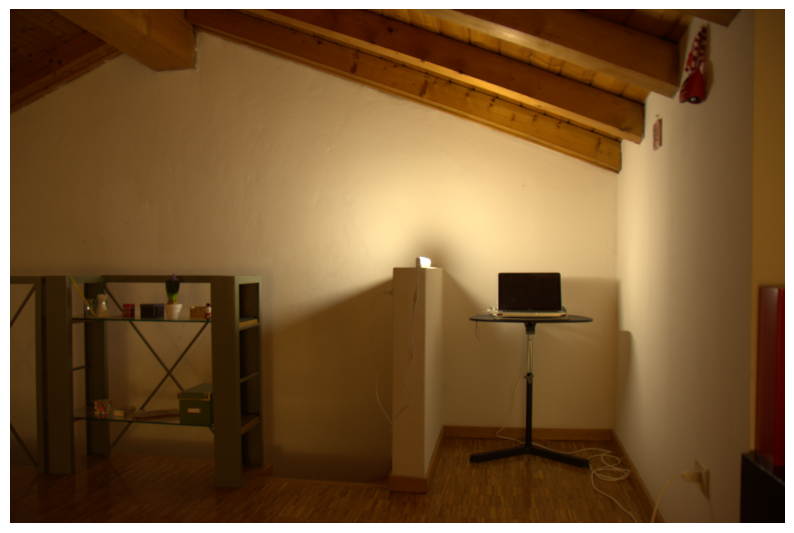

In [10]:
import matplotlib.pyplot as plt

rgb = raw.postprocess(use_camera_wb=True, half_size=True)

print(rgb.shape, rgb.dtype)
print(rgb.min(), rgb.max())

plt.figure(figsize=(10, 7))
plt.imshow(rgb)
plt.axis('off')
plt.show()

In [11]:
import numpy as np

linear_16bit = raw.postprocess(
    use_camera_wb=True,
    gamma=(1, 1),            # no gamma curve
    no_auto_bright=True,     # no automatic brightness
    output_bps=16,           # 16 bits per channel
    half_size=True
)

print(linear_16bit.shape, linear_16bit.dtype)
print(linear_16bit.min(), linear_16bit.max())

(1640, 2474, 3) uint16
0 65535


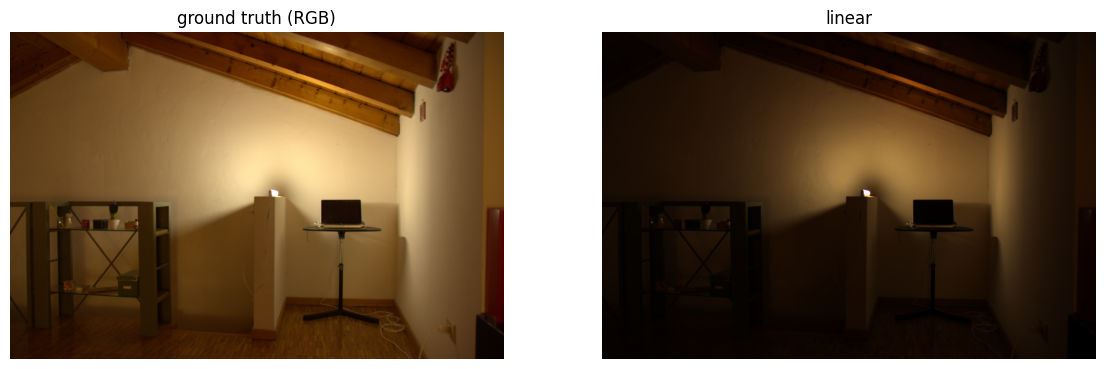

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].imshow(rgb);    axes[0].set_title('ground truth (RGB)')
axes[1].imshow(linear_16bit/ 65535.0); axes[1].set_title('linear')
"""
normalize of the picture - 16 bits -> [0,1], because the values
significantly exceed the standard range expected for integers (255) -> (matplotlib's requirments)
"""
for ax in axes:
    ax.axis('off')
plt.show()

## 4. Symulacja trudnych warunków oświetleniowych

W tej części przygotowujemy obrazy, które będą symulować zdjęcia wykonane w warunkach bardzo słabego oświetlenia. Proces rozpoczynamy od obniżenia ekspozycji obrazu w przestrzeni liniowej światła o 3 EV.

Zmiana ekspozycji jest realizowana poprzez przemnożenie wartości pikseli przez odpowiedni współczynnik. Oznacza to, że ilość światła zostaje zmniejszona ośmiokrotnie.
Następnie stosujemy korekcję gamma, która przekształca obraz do postaci odpowiedniej do wyświetlania. Na końcu konwertujemy obraz do 8-bitowego formatu RGB.

W rezultacie otrzymujemy ciemny obraz, który będzie stanowił wejście dla przygotowywanej sieci neuronowej.

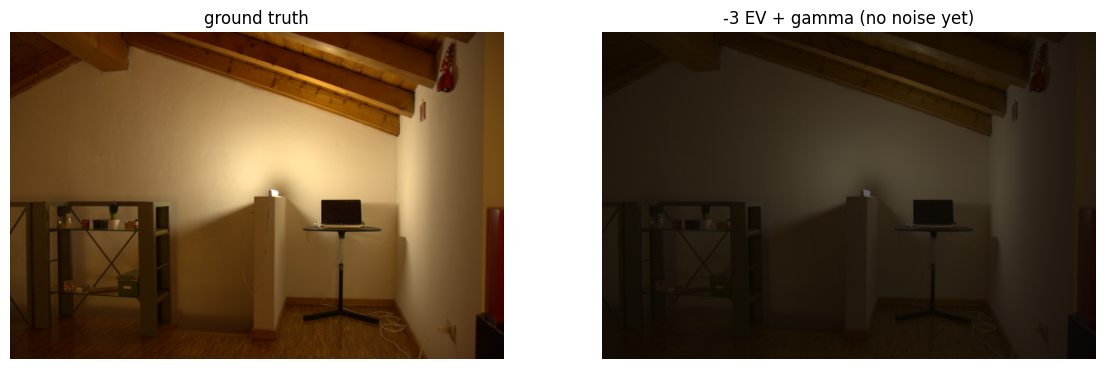

In [14]:
def reduce_exposure(linear_img, ev_shift):
    return linear_img * (2.0 ** ev_shift)                      # -3 EV = 8 times less light = x 1/8


def apply_gamma_correction(img, gamma=2.2):
    return np.power(np.clip(img, 0.0, 1.0), 1.0 / gamma)       # brightens dark tones, for display


def convert_to_8bit(img):
    return (np.clip(img, 0.0, 1.0) * 255).round().astype(np.uint8)


linear = linear_16bit.astype(np.float32) / 65535.0              # linear image, values from 0 to 1

dark_clean = convert_to_8bit(apply_gamma_correction(reduce_exposure(linear, -3.0)))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].imshow(rgb);        axes[0].set_title('ground truth')
axes[1].imshow(dark_clean); axes[1].set_title('-3 EV + gamma (no noise yet)')
for ax in axes:
    ax.axis('off')
plt.show()

## 5. Symulacja szumu matrycy aparatu

Samo obniżenie ekspozycji nie odzwierciedla w pełni rzeczywistych warunków wykonywania zdjęć przy słabym oświetleniu. Dlatego dodatkowo symulujemy szum generowany przez matrycę aparatu.

Wykorzystujemy dwa rodzaje szumu:

- **Szum fotonowy (Poissona)** – wynika z losowego charakteru rejestracji fotonów przez matrycę. Jego wpływ jest szczególnie widoczny przy małej ilości światła.

- **Szum elektroniczny (Gaussa)** – reprezentuje zakłócenia związane z elektroniką aparatu i odczytem sygnału z matrycy.

Oba rodzaje szumu dodajemy do obrazu po obniżeniu ekspozycji, ale przed zastosowaniem korekcji gamma.
Dzięki temu uzyskujemy bardziej realistyczne obrazy wejściowe, które zawierają zarówno niedoświetlenie, jak i zakłócenia charakterystyczne dla pracy aparatu w trudnych warunkach.

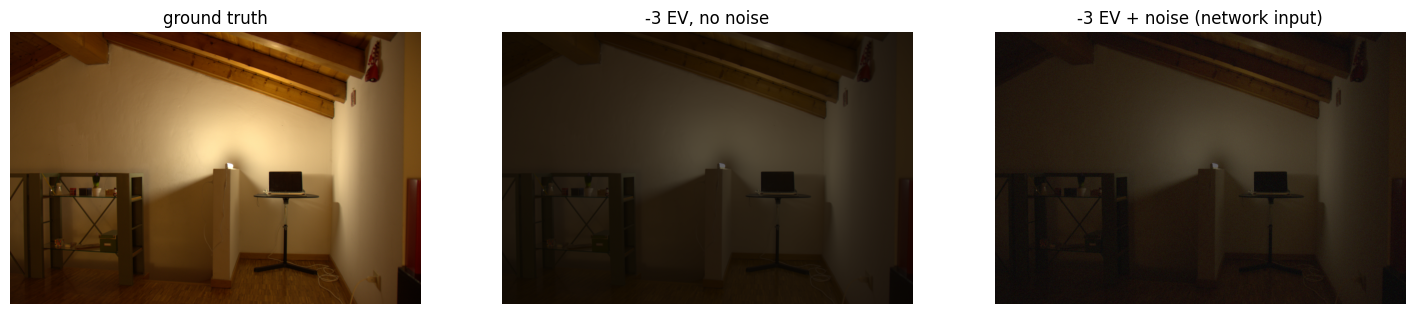

In [15]:
def add_physical_noise(linear_img, alpha=0.001, sigma=0.005):
    noisy_img = np.random.poisson(linear_img / alpha) * alpha          # photon noise
    noisy_img += np.random.normal(0, sigma, linear_img.shape)          # electronic noise
    return np.clip(noisy_img, 0.0, 1.0)


np.random.seed(0)                                                      # the same noise every time

dark_linear = reduce_exposure(linear, -3.0)                            # 1. less light
noisy_dark_linear = add_physical_noise(dark_linear)                    # 2. sensor noise
dark_noisy = convert_to_8bit(apply_gamma_correction(noisy_dark_linear))   # 3. gamma + 8 bit

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].imshow(rgb);         axes[0].set_title('ground truth')
axes[1].imshow(dark_clean);  axes[1].set_title('-3 EV, no noise')
axes[2].imshow(dark_noisy);  axes[2].set_title('-3 EV + noise (network input)')
for ax in axes:
    ax.axis('off')
plt.show()

Wycinek 200 × 200 pikseli, rozjaśniony trzy razy, żeby było widać szum

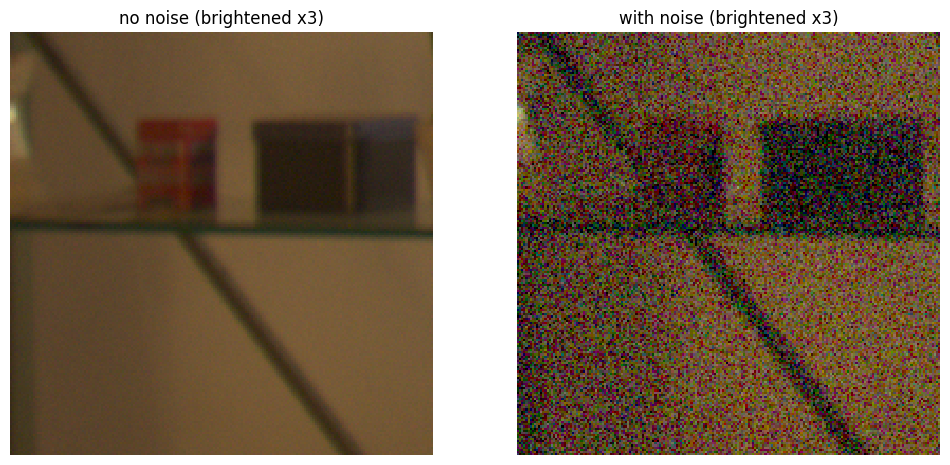

In [16]:
y, x = 900, 300                                                        # top-left corner of the crop
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(np.clip(dark_clean[y:y + 200, x:x + 200] * 3, 0, 255).astype(np.uint8), interpolation='nearest')
axes[0].set_title('no noise (brightened x3)')
axes[1].imshow(np.clip(dark_noisy[y:y + 200, x:x + 200] * 3, 0, 255).astype(np.uint8), interpolation='nearest')
axes[1].set_title('with noise (brightened x3)')
for ax in axes:
    ax.axis('off')
plt.show()

## 6. Generowanie par obrazów Ground Truth i Low Light Input

Po przygotowaniu funkcji przetwarzających obrazy tworzymy kompletny proces generowania danych.

Dla każdego pliku RAW generujemy dwie wersje obrazu:
- plik zakończony `_gt.png` – obraz prawidłowo naświetlony (Ground Truth),
- plik zakończony `_input.png` – obraz z obniżoną ekspozycją i dodanym szumem.

W tym celu wykorzystujemy funkcję `process_single_file()`, która łączy wszystkie wcześniejsze etapy przetwarzania.

Dodatkowo zastosowano powtarzalne ziarno generatora liczb losowych, zależne od nazwy pliku. Dzięki temu dla danego zdjęcia zawsze generowany jest taki sam szum.

Pozwala to zachować powtarzalność eksperymentów oraz zapewnia sprawiedliwe porównanie wyników różnych metod.

In [17]:
import cv2
import zlib


def get_ground_truth(raw):
    return raw.postprocess(use_camera_wb=True, half_size=True)


def get_linear_image(raw):
    linear_16bit = raw.postprocess(use_camera_wb=True, gamma=(1, 1), no_auto_bright=True,
                                   output_bps=16, half_size=True)
    return linear_16bit.astype(np.float32) / 65535.0


def get_low_light(raw, ev_shift=-3.0):
    linear_img = get_linear_image(raw)                         # 1. linear image
    dark_linear = reduce_exposure(linear_img, ev_shift)        # 2. less light
    noisy_dark_linear = add_physical_noise(dark_linear)        # 3. sensor noise
    dark_srgb = apply_gamma_correction(noisy_dark_linear)      # 4. gamma
    return convert_to_8bit(dark_srgb)                          # 5. 8 bit


def save_png(path, img_rgb):
    cv2.imwrite(path, cv2.cvtColor(img_rgb, cv2.COLOR_RGB2BGR))     # OpenCV saves BGR, not RGB


def process_single_file(file_path, gt_dir, dark_dir, ev_shift=-3.0):
    base_name = os.path.splitext(os.path.basename(file_path))[0]
    gt_path = os.path.join(gt_dir, f'{base_name}_gt.png')
    dark_path = os.path.join(dark_dir, f'{base_name}_input.png')
    if os.path.exists(gt_path) and os.path.exists(dark_path):
        print(f'Skipping {base_name} - already processed.')
        return
    print(f'Processing {base_name}...')
    np.random.seed(zlib.crc32(base_name.encode()) % (2 ** 32))      # the same noise every time for the same file
    with rawpy.imread(file_path) as raw_file:
        save_png(gt_path, get_ground_truth(raw_file))
        save_png(dark_path, get_low_light(raw_file, ev_shift))

Test na 3 pobranych plikach

In [18]:
gt_dir = '/content/lowlight_data/gt'
dark_dir = '/content/lowlight_data/dark'
os.makedirs(gt_dir, exist_ok=True)
os.makedirs(dark_dir, exist_ok=True)

for file_id in df['File'].iloc[:3]:
    process_single_file(f'/content/raise_nef/{file_id}.NEF', gt_dir, dark_dir)

!ls -lh {gt_dir} {dark_dir}

Processing rfcf40796t...
Processing ra5689909t...
Processing r5714d7e2t...
/content/lowlight_data/dark:
total 26M
-rw-r--r-- 1 root root 8.3M Nov 14 11:49 r5714d7e2t_input.png
-rw-r--r-- 1 root root 8.4M Nov 14 11:49 ra5689909t_input.png
-rw-r--r-- 1 root root 8.5M Nov 14 11:49 rfcf40796t_input.png

/content/lowlight_data/gt:
total 20M
-rw-r--r-- 1 root root 6.7M Nov 14 11:49 r5714d7e2t_gt.png
-rw-r--r-- 1 root root 6.3M Nov 14 11:49 ra5689909t_gt.png
-rw-r--r-- 1 root root 6.4M Nov 14 11:49 rfcf40796t_gt.png


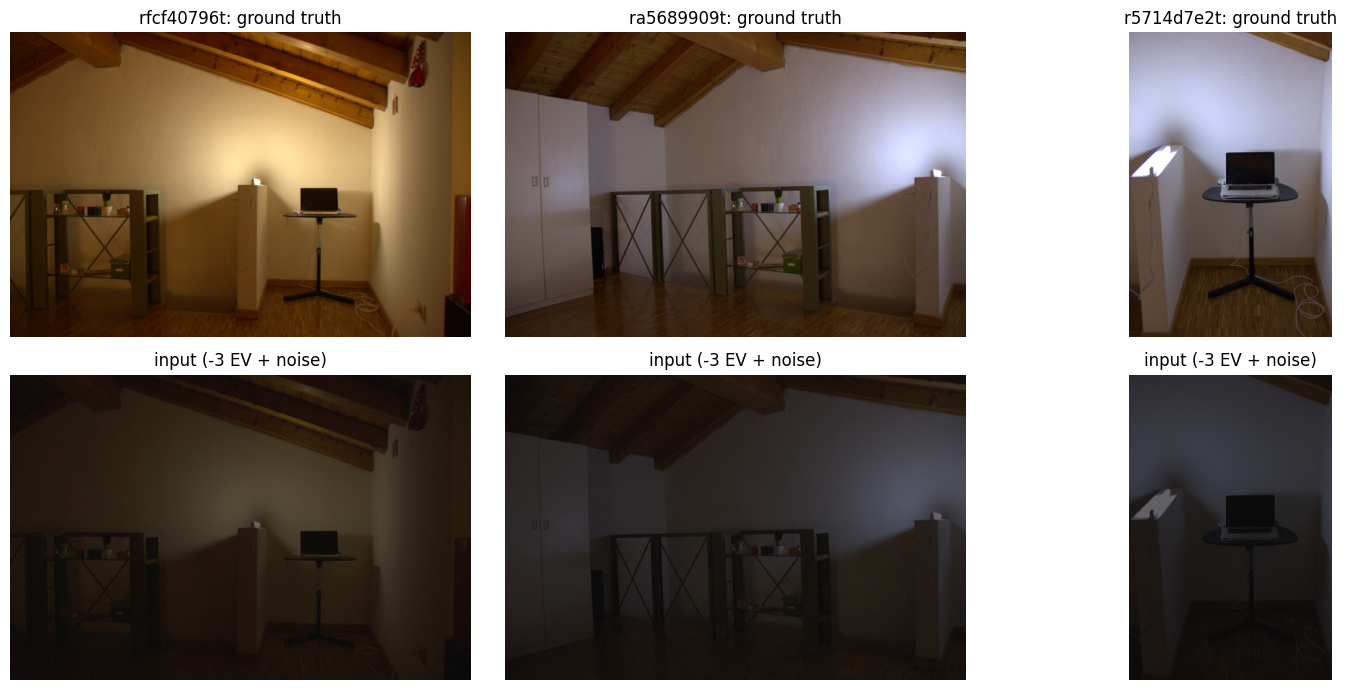

In [19]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for j, file_id in enumerate(df['File'].iloc[:3]):
    gt = cv2.cvtColor(cv2.imread(f'{gt_dir}/{file_id}_gt.png'), cv2.COLOR_BGR2RGB)
    dark = cv2.cvtColor(cv2.imread(f'{dark_dir}/{file_id}_input.png'), cv2.COLOR_BGR2RGB)
    axes[0, j].imshow(gt);   axes[0, j].set_title(f'{file_id}: ground truth')
    axes[1, j].imshow(dark); axes[1, j].set_title('input (-3 EV + noise)')
for ax in axes.flat:
    ax.axis('off')
plt.tight_layout()
plt.show()

Szum ma stałe ziarno zależne od nazwy pliku, więc ten sam plik zawsze dostaje identyczny szum. Ciemne obrazy testowe nie zmieniają się przy ponownym uruchomieniu, a baseline i sieć są oceniane na tych samych danych.
Jeśli oba pliki już istnieją, funkcja je pomija, więc można ją uruchomić drugi raz po przerwaniu.

## 7. Przygotowanie pełnego zbioru danych

Po sprawdzeniu poprawności działania przygotowanych funkcji na trzech przykładowych zdjęciach przechodzimy do przetwarzania większej liczby danych.

Pobieramy pierwsze 100 zdjęć z pliku CSV, a następnie dla każdego z nich generujemy parę obrazów Ground Truth oraz Low Light Input.

Wygenerowane obrazy zapisujemy w dwóch oddzielnych katalogach:
- `gt` – obrazy referencyjne,
- `dark` – obrazy niedoświetlone z zasymulowanym szumem.

Na końcu sprawdzamy liczbę wygenerowanych plików i zapisujemy przygotowany zbiór na Google Drive, aby można było wykorzystać go w kolejnych etapach projektu.

In [20]:
import glob

download_raise_nef('/content/RAISE_258.csv', '/content/raise_nef', limit=100)

files = glob.glob('/content/raise_nef/*.NEF')
print(len(files), 'files,', round(sum(os.path.getsize(f) for f in files) / 1e9, 2), 'GB')

Skipping rfcf40796t.NEF - already exists.
Skipping ra5689909t.NEF - already exists.
Skipping r5714d7e2t.NEF - already exists.
100 files, 2.01 GB


In [21]:
for file_id in df['File'].iloc[:100]:
    try:
        process_single_file(f'/content/raise_nef/{file_id}.NEF', gt_dir, dark_dir)
    except Exception as e:
        print('ERROR', file_id, e)

print('gt:', len(os.listdir(gt_dir)), '| dark:', len(os.listdir(dark_dir)))

Skipping rfcf40796t - already processed.
Skipping ra5689909t - already processed.
Skipping r5714d7e2t - already processed.
Processing r286398d1t...
Processing r2f686f2ct...
Processing reaead240t...
Processing rc204d944t...
Processing r1ced1907t...
Processing r3c238fbbt...
Processing rf9565175t...
Processing rcffd112dt...
Processing r35ddb730t...
Processing r8d970f8ft...
Processing rd7da5109t...
Processing rfc7c97b4t...
Processing rb1bee05ft...
Processing r49c201d2t...
Processing rf8319011t...
Processing r3e8f32cdt...
Processing r14df59fet...
Processing r5d97aeb9t...
Processing rd15606ect...
Processing r9c4179fft...
Processing r37afc519t...
Processing re6b950a6t...
Processing r0e63ca9ft...
Processing rbfcec858t...
Processing r12cebbd2t...
Processing r3ed6e1bct...
Processing r059ce7d0t...
Processing rd3bf3494t...
Processing r1ca0784dt...
Processing r36c7ecc6t...
Processing r81a0d30et...
Processing r388ede2at...
Processing raebf8343t...
Processing r320f56f1t...
Processing r42037e1at...
Pr

In [22]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [23]:
!mkdir -p /content/drive/MyDrive/sigk_lowlight
!cp -r /content/lowlight_data /content/drive/MyDrive/sigk_lowlight/
!ls /content/drive/MyDrive/sigk_lowlight/lowlight_data

dark  gt


## 8. Podsumowanie

W ramach notebooka przeprowadzono proces przygotowania danych do projektu Low Light Image Enhancement.

Zrealizowane etapy obejmowały:
1. Analizę metadanych zbioru RAISE.
2. Pobranie zdjęć RAW w formacie NEF.
3. Konwersję zdjęć do przestrzeni RGB.
4. Przygotowanie obrazów referencyjnych Ground Truth.
5. Obniżenie ekspozycji o 3 EV w przestrzeni liniowej.
6. Symulację szumu fotonowego Poissona oraz szumu elektronicznego Gaussa.
7. Wygenerowanie i zapis par obrazów wejściowych oraz referencyjnych.

Otrzymany zbiór danych stanowi podstawę do dalszego etapu projektu, czyli trenowania sieci neuronowej mającej na celu poprawę jakości zdjęć wykonanych przy słabym oświetleniu.